In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from pathlib import Path

dataset_path = Path('/content/drive/MyDrive/plantvillage')

print(dataset_path.exists())
print(len(list(dataset_path.iterdir())))

True
10


In [4]:
classes = [folder.name for folder in dataset_path.iterdir() if folder.is_dir()]
classes

['Tomato___Tomato_Yellow_Leaf_Curl_Virus',
 'Tomato___Target_Spot',
 'Tomato___Late_blight',
 'Tomato___healthy',
 'Tomato___Tomato_mosaic_virus',
 'Tomato___Spider_mites Two-spotted_spider_mite',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Early_blight',
 'Tomato___Bacterial_spot']

In [5]:
image_counts = {}

for cls in classes:
    class_path = dataset_path / cls
    image_counts[cls] = len(list(class_path.glob('*')))

image_counts

{'Tomato___Tomato_Yellow_Leaf_Curl_Virus': 4286,
 'Tomato___Target_Spot': 1123,
 'Tomato___Late_blight': 1527,
 'Tomato___healthy': 1273,
 'Tomato___Tomato_mosaic_virus': 299,
 'Tomato___Spider_mites Two-spotted_spider_mite': 1341,
 'Tomato___Leaf_Mold': 761,
 'Tomato___Septoria_leaf_spot': 1417,
 'Tomato___Early_blight': 800,
 'Tomato___Bacterial_spot': 1703}

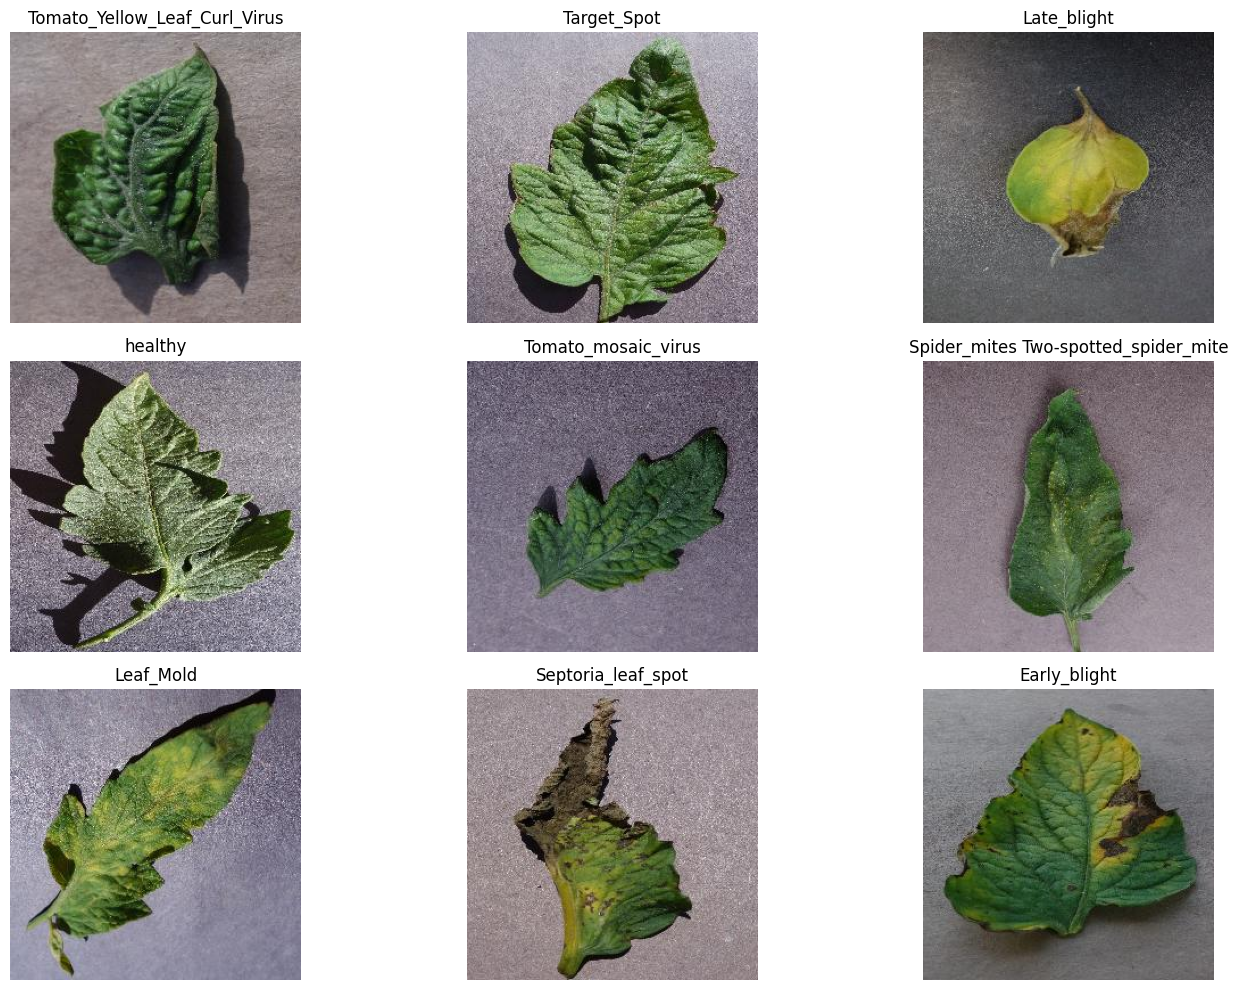

In [6]:
import matplotlib.pyplot as plt
from PIL import Image
import random

plt.figure(figsize=(15, 10))

for i, cls in enumerate(classes[:9]):
    class_path = dataset_path / cls
    img_path = random.choice(list(class_path.glob('*')))
    img = Image.open(img_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(cls.replace("Tomato___", ""))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
#checking the version of tensorflow
import tensorflow as tf

print(tf.__version__)


2.20.0


In [8]:
#loading dataset 
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="both",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

train_ds, val_ds = dataset

Found 14530 files belonging to 10 classes.


Using 11624 files for training.
Using 2906 files for validation.


In [9]:
#checking the class labels numeric values
class_names = train_ds.class_names
class_names

['Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_spider_mite',
 'Tomato___Target_Spot',
 'Tomato___Tomato_Yellow_Leaf_Curl_Virus',
 'Tomato___Tomato_mosaic_virus',
 'Tomato___healthy']

In [10]:
#optimize dataset pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [11]:
#data augmentation for balancing the dataset
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2),
])

In [12]:
#Load Pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [13]:
#freeze the base model
base_model.trainable = False


In [14]:
#building the full model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(10, activation='softmax')(x)

model = tf.keras.Model(inputs, outputs)

In [15]:
#compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

#model summary
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
#checking if GPU is available
import tensorflow as tf
tf.config.list_physical_devices('GPU')

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

: 

In [17]:
#training
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5903 - loss: 1.2429

: 

: 